# DSC 411/511 Project
# Notebook 03: RQ1: Can We Predict a Positive Building Payment?

**Class topics:** Lecture 05 (decision trees, naive Bayes), Lecture 06 (k-NN), Lecture 07 (logistic
regression, SVM, evaluation, ROC, cross-validation, leakage, imbalance), Lecture 14 (neural networks).

---

> **RQ1. Can policy, building and external event information predict whether a claim receives a
> positive building payment (`amountPaidOnBuildingClaim > 0`)?**

**Why it matters.** About one claim in five closes with no building payment. Each one still costs an
adjuster visit. If we could tell at filing time which claims will probably not pay, the program could
route them to a faster desk review, and spend field time on the claims that will pay.

**How this notebook moves.** We first study each classifier from the course on this problem, one
at a time, and explain how it decides. Then we compare them, and finally we answer the question
with three feature sets: **NFIP only**, **+ event data**, **+ context data**.

---
# Section 0: Setup

In [1]:
import sys
import time
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GroupKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, balanced_accuracy_score, f1_score,
                             confusion_matrix, roc_curve, precision_recall_curve, classification_report)
import lightgbm as lgb
import shap

sys.path.append('/Users/home/workspace/School/DataMining/nfip_claims')
from nfip_project_utils import *

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
pd.set_option('display.width', 180)

claims = load_clean_claims()
TARGET = 'building_paid_flag'
train_claims = claims[claims['loss_year'].isin(TRAIN_YEARS)].reset_index(drop=True)
test_claims = claims[claims['loss_year'].isin(TEST_YEARS)].reset_index(drop=True)
print(f'Train (2020-2023): {len(train_claims):,} claims, paid rate {train_claims[TARGET].mean() * 100:.1f}%')
print(f'Test  (2024-2025): {len(test_claims):,} claims, paid rate {test_claims[TARGET].mean() * 100:.1f}%')

Train (2020-2023): 147,642 claims, paid rate 80.7%
Test  (2024-2025): 105,482 claims, paid rate 86.8%


---
# Section 1: The Target and the Baseline

The classes are not balanced: most claims are paid. A model that always says "paid" is right most of the
time and useless. Lecture 07, Section 6: **accuracy is not enough**. We report:

- **ROC-AUC**: the probability that a random paid claim gets a higher score than a random unpaid claim.
  0.5 = coin flip, 1.0 = perfect.
- **PR-AUC for the "not paid" class**: how well we find the minority class. A random model scores the
  share of unpaid claims.
- **Balanced accuracy**: the mean of the recall on each class.

In [2]:
print('Paid rate by year (%):')
print((claims.groupby('loss_year')[TARGET].mean() * 100).round(1).to_string())
majority_accuracy = test_claims[TARGET].mean()
print(f'\nAlways-"paid" baseline accuracy on test: {majority_accuracy * 100:.1f}%')
print(f'Random PR-AUC for the "not paid" class : {(1 - majority_accuracy):.3f}')

Paid rate by year (%):
loss_year
2020    77.3
2021    81.0
2022    81.7
2023    82.5
2024    87.0
2025    85.8

Always-"paid" baseline accuracy on test: 86.8%
Random PR-AUC for the "not paid" class : 0.132


---
# Section 2: Evaluation Design (how we avoid fooling ourselves)

1. **Time split.** Train on 2020-2023, test on 2024-2025. The test storms (Helene, Milton, Debby,
   Francine, Beryl) were never seen in training. This is "time travel" protection (Lecture 07, Section 11).
2. **Event-grouped cross-validation inside the training years.** Claims from one storm are similar to
   each other. A random K-fold would put Ian claims in both train and validation folds and look too good.
   `GroupKFold` keeps each event in one fold only.
3. **Every preprocessing step inside a Pipeline**, fitted on training rows only.
4. **Thresholds are tuned on 2023**, never on the test years.
5. **No leaking columns.** `check_no_leakage` stops the notebook if one slips in.

In [3]:
numeric_A, categorical_A = FEATURE_SETS['A. NFIP only']
numeric_C, categorical_C = FEATURE_SETS['C. NFIP + event + context (ACS, NRI)']
for name, (numeric, categorical) in FEATURE_SETS.items():
    check_no_leakage(numeric + categorical)
    print(f'{name:<45} numeric {len(numeric):>3}   categorical {len(categorical)}')

# Smaller samples for the slow, distance-based methods (k-NN, SVM). Same rows for every model.
model_sample_train = train_claims.sample(30_000, random_state=SEED)
model_sample_test = test_claims.sample(20_000, random_state=SEED)
print(f'\nComparison sample: train {len(model_sample_train):,}, test {len(model_sample_test):,}')

A. NFIP only                                  numeric  23   categorical 8
B. NFIP + event (PRISM, HURDAT2, coast)       numeric  35   categorical 8
C. NFIP + event + context (ACS, NRI)          numeric  50   categorical 8

Comparison sample: train 30,000, test 20,000


---
# Section 3: Decision Tree (Lecture 05)

## 3.1 How a tree picks a split, by hand

A tree asks yes/no questions. At each node it tries every feature and every cut point, and keeps
the one that makes the two children **purest**. Purity is measured with **Gini impurity**:

Gini = 1 - p(paid)^2 - p(not paid)^2

Gini is 0 for a pure node and 0.5 for a 50/50 node. The quality of a split is the drop in
Gini, weighted by the size of each child. We compute it by hand for one feature: 3-day rain.

In [4]:
def gini(labels):
    share_paid = labels.mean()
    return 1 - share_paid ** 2 - (1 - share_paid) ** 2


parent = model_sample_train[TARGET]
print(f'Parent node: {len(parent):,} claims, paid {parent.mean() * 100:.1f}%, Gini = {gini(parent):.4f}\n')
split_rows = []
for cut in [5, 10, 20, 40, 60, 100, 150]:
    left = model_sample_train.loc[model_sample_train['rain_3day_mm'] <= cut, TARGET]
    right = model_sample_train.loc[model_sample_train['rain_3day_mm'] > cut, TARGET]
    weighted_child_gini = (len(left) * gini(left) + len(right) * gini(right)) / len(parent)
    split_rows.append({'cut: rain_3day_mm <=': cut, 'left_n': len(left), 'left_paid_%': round(left.mean() * 100, 1),
                       'right_n': len(right), 'right_paid_%': round(right.mean() * 100, 1),
                       'weighted_child_gini': round(weighted_child_gini, 4),
                       'gini_decrease': round(gini(parent) - weighted_child_gini, 4)})
print(pd.DataFrame(split_rows).to_string(index=False))

Parent node: 30,000 claims, paid 80.6%, Gini = 0.3126

 cut: rain_3day_mm <=  left_n  left_paid_%  right_n  right_paid_%  weighted_child_gini  gini_decrease
                    5     979         50.4    29021          81.6               0.3064         0.0062
                   10    1271         49.6    28729          82.0               0.3041         0.0085
                   20    1962         54.4    28038          82.4               0.3029         0.0096
                   40    2978         59.6    27022          82.9               0.3028         0.0097
                   60    4266         65.2    25734          83.2               0.3047         0.0078
                  100    7751         72.6    22249          83.4               0.3081         0.0045
                  150   13743         78.1    16257          82.8               0.3115         0.0011


The best cut is the one with the largest Gini decrease. Claims with very little rain are paid less
often: many of them are "not actual flood" or "below deductible". The tree repeats this search
at every node, for every feature.

## 3.2 Depth and overfitting (Lecture 05, Section 4)

max_depth  train_ROC_AUC  test_ROC_AUC
        2         0.5999        0.5798
        3         0.6597        0.6119
        4         0.6882        0.6420
        6         0.7384        0.6687
        8         0.7705        0.7058
       10         0.8026        0.6845
       14         0.8448        0.6568
       20         0.8664        0.6549
     None         0.8702        0.6544


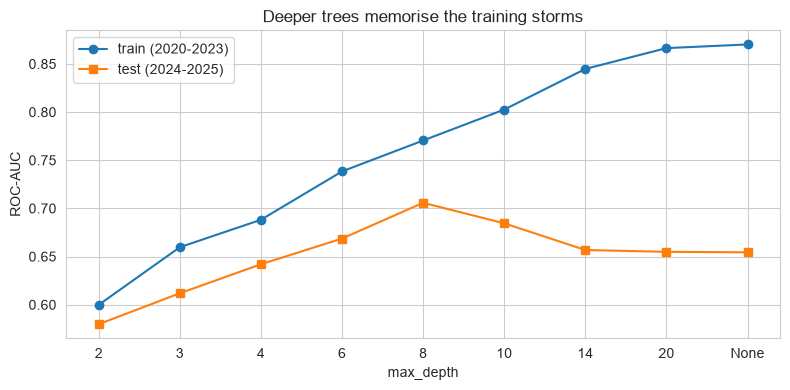

In [5]:
tree_preprocessor = make_preprocessor(numeric_C, categorical_C, scale=False)   # trees do not need scaling
train_matrix_tree = tree_preprocessor.fit_transform(train_claims)
test_matrix_tree = tree_preprocessor.transform(test_claims)
tree_feature_names = list(tree_preprocessor.get_feature_names_out())

depth_rows = []
for depth in [2, 3, 4, 6, 8, 10, 14, 20, None]:
    tree = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=50, random_state=SEED, class_weight='balanced')
    tree.fit(train_matrix_tree, train_claims[TARGET])
    depth_rows.append({'max_depth': str(depth),
                       'train_ROC_AUC': roc_auc_score(train_claims[TARGET], tree.predict_proba(train_matrix_tree)[:, 1]),
                       'test_ROC_AUC': roc_auc_score(test_claims[TARGET], tree.predict_proba(test_matrix_tree)[:, 1])})
depth_table = pd.DataFrame(depth_rows).round(4)
print(depth_table.to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(depth_table['max_depth'], depth_table['train_ROC_AUC'], 'o-', label='train (2020-2023)')
ax.plot(depth_table['max_depth'], depth_table['test_ROC_AUC'], 's-', label='test (2024-2025)')
ax.set_xlabel('max_depth')
ax.set_ylabel('ROC-AUC')
ax.set_title('Deeper trees memorise the training storms')
ax.legend()
plt.tight_layout()
plt.savefig(FIGURE_DIR / '03_tree_depth.png', dpi=120)
plt.show()

## 3.3 What a small tree learned

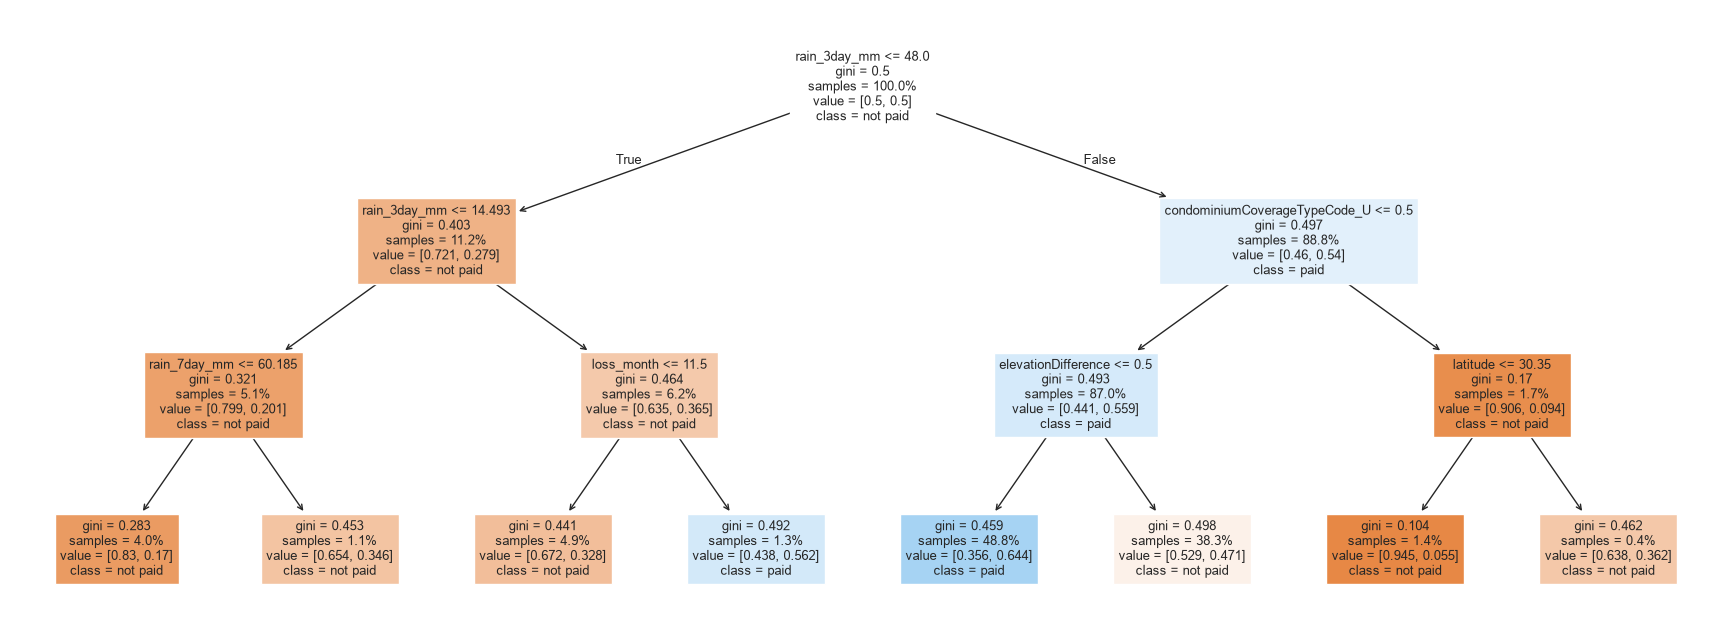

|--- rain_3day_mm <= 48.00
|   |--- rain_3day_mm <= 14.49
|   |   |--- rain_7day_mm <= 60.18
|   |   |   |--- class: 0
|   |   |--- rain_7day_mm >  60.18
|   |   |   |--- class: 0
|   |--- rain_3day_mm >  14.49
|   |   |--- loss_month <= 11.50
|   |   |   |--- class: 0
|   |   |--- loss_month >  11.50
|   |   |   |--- class: 1
|--- rain_3day_mm >  48.00
|   |--- condominiumCoverageTypeCode_U <= 0.50
|   |   |--- elevationDifference <= 0.50
|   |   |   |--- class: 1
|   |   |--- elevationDifference >  0.50
|   |   |   |--- class: 0
|   |--- condominiumCoverageTypeCode_U >  0.50
|   |   |--- latitude <= 30.35
|   |   |   |--- class: 0
|   |   |--- latitude >  30.35
|   |   |   |--- class: 0



In [6]:
small_tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=200, random_state=SEED, class_weight='balanced')
small_tree.fit(train_matrix_tree, train_claims[TARGET])
fig, ax = plt.subplots(figsize=(22, 8))
plot_tree(small_tree, feature_names=tree_feature_names, class_names=['not paid', 'paid'], filled=True, fontsize=9,
          proportion=True, impurity=True, ax=ax)
plt.savefig(FIGURE_DIR / '03_small_tree.png', dpi=100)
plt.show()
print(export_text(small_tree, feature_names=tree_feature_names, max_depth=3))

---
# Section 4: Naive Bayes (Lecture 05, Sections 7-8)

Bayes' rule: P(paid | features) is proportional to P(paid) x P(feature 1 | paid) x P(feature 2 | paid) x ...

The **naive** part is the multiplication: it assumes the features are independent inside each class.
`GaussianNB` also assumes each feature is a bell curve inside each class. It stores only a mean and a
variance per feature per class.

In [7]:
nb_preprocessor = make_preprocessor(numeric_C, categorical_C, scale=True)
nb_train = nb_preprocessor.fit_transform(model_sample_train)
nb_test = nb_preprocessor.transform(model_sample_test)
naive_bayes = GaussianNB().fit(nb_train, model_sample_train[TARGET])
nb_names = list(nb_preprocessor.get_feature_names_out())
stored = pd.DataFrame({'mean | not paid': naive_bayes.theta_[0], 'mean | paid': naive_bayes.theta_[1],
                       'var | not paid': naive_bayes.var_[0], 'var | paid': naive_bayes.var_[1]}, index=nb_names)
stored['mean_gap'] = (stored['mean | paid'] - stored['mean | not paid']).abs()
print('What the model stores (scaled units), 8 features with the biggest class gap:')
print(stored.sort_values('mean_gap', ascending=False).head(8).round(3).to_string())
nb_scores = naive_bayes.predict_proba(nb_test)[:, 1]
print(f'\nNaive Bayes test ROC-AUC (sample): {roc_auc_score(model_sample_test[TARGET], nb_scores):.4f}')

What the model stores (scaled units), 8 features with the biggest class gap:
                               mean | not paid  mean | paid  var | not paid  var | paid  mean_gap
postFIRMConstructionIndicator            0.204       -0.049           1.034       0.979     0.253
building_age_at_loss                    -0.194        0.047           0.970       0.996     0.241
in_special_flood_hazard_area            -0.193        0.047           1.217       0.937     0.240
rain_3day_mm                            -0.187        0.045           1.086       0.969     0.232
rain_max_daily_7day_mm                  -0.173        0.042           1.019       0.986     0.215
rain_7day_mm                            -0.166        0.040           1.082       0.972     0.206
longitude                               -0.148        0.036           1.133       0.962     0.183
acs_pct_non_hispanic_white              -0.138        0.033           1.091       0.972     0.172

Naive Bayes test ROC-AUC (sample): 0.622

**Why naive Bayes struggles here.** Rain over 1, 3 and 7 days are strongly correlated, so naive Bayes
counts the same evidence three times. Dollar and rain columns are skewed, not bell-shaped. Both
assumptions from Lecture 05 Section 8 are broken.

---
# Section 5: k-Nearest Neighbours (Lecture 06)

k-NN has no training step. To score a claim it finds the k most similar past claims (by Euclidean
distance on scaled features) and takes the share that were paid. Scaling is required: without it,
coverage in dollars would decide every distance (Lecture 06, Sections 1-2).

In [8]:
knn_rows = []
for k in [5, 15, 51, 151]:
    start = time.time()
    knn = KNeighborsClassifier(n_neighbors=k, n_jobs=4).fit(nb_train, model_sample_train[TARGET])
    knn_scores = knn.predict_proba(nb_test)[:, 1]
    knn_rows.append({'k': k, 'test_ROC_AUC': round(roc_auc_score(model_sample_test[TARGET], knn_scores), 4),
                     'seconds_to_predict_20k': round(time.time() - start, 1)})
print(pd.DataFrame(knn_rows).to_string(index=False))

  k  test_ROC_AUC  seconds_to_predict_20k
  5        0.6455                     0.4
 15        0.6825                     0.4
 51        0.6943                     0.4
151        0.6951                     0.5


Small k overfits to single neighbours. Larger k smooths the vote and does better. k-NN is slow at
prediction time (Lecture 06, Section 6): every new claim is compared with all 30,000 stored claims.

---
# Section 6: Logistic Regression (Lecture 07, Section 1)

Add up every feature with a weight, then squash the sum into a probability with the sigmoid:

z = b0 + b1 x1 + b2 x2 + ...      p(paid) = 1 / (1 + e^(-z))

The weights are found by maximising the likelihood of the training labels. Because the features are
scaled, the size of a weight shows how strongly a one-standard-deviation change moves the log-odds.

In [9]:
logistic_pipeline = Pipeline([('prep', make_preprocessor(numeric_C, categorical_C, scale=True)),
                              ('model', LogisticRegression(max_iter=3000, C=0.5))])
logistic_pipeline.fit(train_claims, train_claims[TARGET])
logistic_names = logistic_pipeline.named_steps['prep'].get_feature_names_out()
coefficients = pd.Series(logistic_pipeline.named_steps['model'].coef_[0], index=logistic_names)
intercept = logistic_pipeline.named_steps['model'].intercept_[0]

one_claim = test_claims.iloc[[0]]
scaled_row = logistic_pipeline.named_steps['prep'].transform(one_claim)[0]
z_value = intercept + scaled_row @ coefficients.values
print('ONE CLAIM, TRACED END TO END')
print(f'   event: {one_claim["floodEvent"].iloc[0]}, state {one_claim["state"].iloc[0]}, '
      f'3-day rain {one_claim["rain_3day_mm"].iloc[0]:.0f} mm, storm distance {one_claim["storm_distance_km"].iloc[0]:.0f} km')
print(f'STEP 1  z = {intercept:+.3f} (intercept) + sum of weight x value = {z_value:.3f}')
contributions = pd.Series(scaled_row * coefficients.values, index=logistic_names).sort_values(key=abs, ascending=False)
for name, value in contributions.head(5).items():
    print(f'           {value:+.3f} from {name}')
print(f'STEP 2  p = 1 / (1 + e^(-{z_value:.3f})) = {1 / (1 + np.exp(-z_value)):.3f}')
print(f'STEP 3  truth: {"paid" if one_claim[TARGET].iloc[0] == 1 else "not paid"}')

ONE CLAIM, TRACED END TO END
   event: nan, state ME, 3-day rain 43 mm, storm distance 2000 km
STEP 1  z = +0.464 (intercept) + sum of weight x value = 1.430
           -0.847 from storm_category_at_closest
           +0.650 from condominiumCoverageTypeCode_N
           +0.606 from storm_wind_at_closest_kt
           -0.567 from latitude
           -0.480 from has_contents_coverage
STEP 2  p = 1 / (1 + e^(-1.430)) = 0.807
STEP 3  truth: not paid


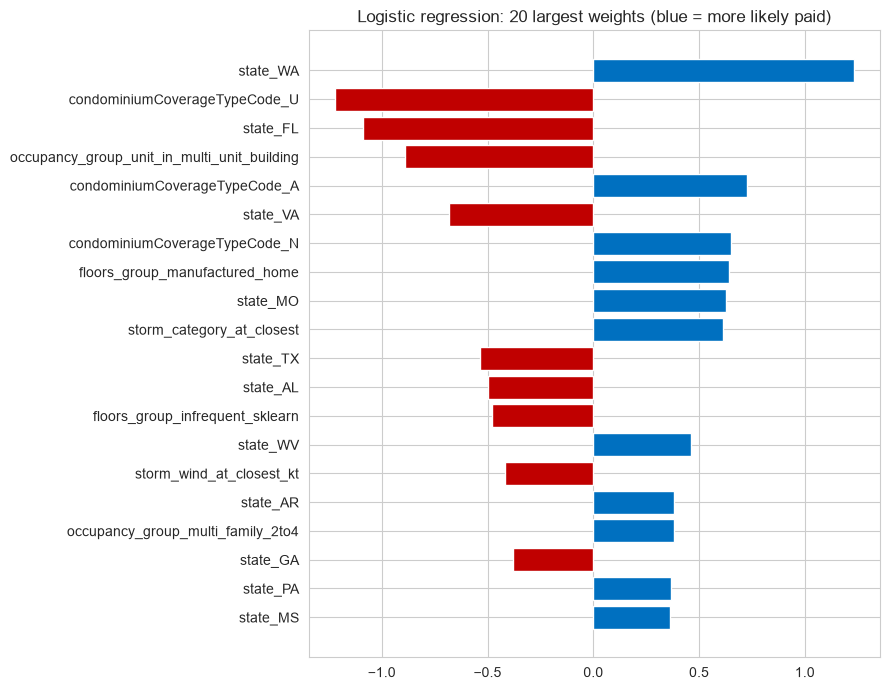

In [10]:
top_coefficients = coefficients.sort_values(key=abs, ascending=False).head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(top_coefficients.index, top_coefficients.values, color=np.where(top_coefficients.values > 0, '#0070C0', '#C00000'))
ax.set_title('Logistic regression: 20 largest weights (blue = more likely paid)')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '03_logistic_coefficients.png', dpi=120)
plt.show()

---
# Section 7: Support Vector Machine (Lecture 07, Sections 3-4)

An SVM looks for the boundary with the **widest margin** between the classes. Only the claims closest
to the boundary (the support vectors) decide where it goes. With the RBF kernel the boundary can curve.
SVM training grows faster than linearly with the number of rows, so we use the 30,000-row sample.

In [11]:
start = time.time()
svm_model = SVC(kernel='rbf', C=1.0, gamma='scale', probability=False, random_state=SEED)
svm_model.fit(nb_train, model_sample_train[TARGET])
svm_scores = svm_model.decision_function(nb_test)
print(f'SVM (RBF) trained in {time.time() - start:.0f} s')
print(f'Support vectors: {svm_model.n_support_.sum():,} of {len(nb_train):,} training claims '
      f'({svm_model.n_support_.sum() / len(nb_train) * 100:.0f}%)')
print(f'SVM test ROC-AUC (sample): {roc_auc_score(model_sample_test[TARGET], svm_scores):.4f}')

SVM (RBF) trained in 63 s
Support vectors: 13,059 of 30,000 training claims (44%)
SVM test ROC-AUC (sample): 0.6963


A large share of the claims are support vectors. That tells us the two classes **overlap heavily**:
many paid and unpaid claims look alike in these features.

---
# Section 8: Neural Network (Lecture 14)

A multi-layer perceptron stacks layers of "weighted sum + non-linear function". It can learn
interactions on its own. Lecture 14's lesson: on tabular data with good columns it often does **not**
beat simpler models. We test that here.

In [12]:
start = time.time()
mlp_pipeline = Pipeline([('prep', make_preprocessor(numeric_C, categorical_C, scale=True)),
                         ('model', MLPClassifier(hidden_layer_sizes=(64, 32), alpha=1e-3, batch_size=512,
                                                 early_stopping=True, max_iter=60, random_state=SEED))])
mlp_pipeline.fit(train_claims, train_claims[TARGET])
mlp_test_scores = mlp_pipeline.predict_proba(test_claims)[:, 1]
print(f'MLP trained in {time.time() - start:.0f} s, stopped after {mlp_pipeline.named_steps["model"].n_iter_} epochs')
print(f'MLP test ROC-AUC (full test): {roc_auc_score(test_claims[TARGET], mlp_test_scores):.4f}')

MLP trained in 6 s, stopped after 26 epochs
MLP test ROC-AUC (full test): 0.7739


---
# Section 9: Gradient Boosting (LightGBM), one step beyond the course

Boosting builds many small trees **in sequence**. Each new tree is fitted to the errors (the gradient
of the loss) left by the trees before it. The result is a strong model built from weak ones.
LightGBM handles categories and missing values natively and trains fast on 150,000 rows.

In [13]:
def fit_lightgbm(train_rows, numeric, categorical, n_estimators=500):
    model = lgb.LGBMClassifier(n_estimators=n_estimators, learning_rate=0.03, num_leaves=63, min_child_samples=100,
                               subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=1.0,
                               random_state=SEED, verbose=-1)
    model.fit(to_category_frame(train_rows, numeric, categorical), train_rows[TARGET])
    return model


lightgbm_C = fit_lightgbm(train_claims, numeric_C, categorical_C)
lightgbm_test_scores = lightgbm_C.predict_proba(to_category_frame(test_claims, numeric_C, categorical_C))[:, 1]
print(f'LightGBM test ROC-AUC (full test): {roc_auc_score(test_claims[TARGET], lightgbm_test_scores):.4f}')

LightGBM test ROC-AUC (full test): 0.7820


---
# Section 10: All Models, One Table (Lecture 06, Section 7: "three methods, one question")

Every model is scored on the **same 20,000 test claims**. Trees, logistic, MLP and LightGBM were trained
on all training rows. k-NN, naive Bayes and SVM were trained on the 30,000-row sample.

In [14]:
sample_index = model_sample_test.index
sample_target = model_sample_test[TARGET].values
test_sample_rows = test_claims.loc[sample_index] if False else model_sample_test


def score_row(name, scores, training_rows):
    not_paid_scores = -np.asarray(scores)
    return {'model': name, 'trained_on': training_rows,
            'ROC_AUC': roc_auc_score(sample_target, scores),
            'PR_AUC_not_paid': average_precision_score(1 - sample_target, not_paid_scores)}


best_tree = DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, random_state=SEED, class_weight='balanced')
best_tree.fit(train_matrix_tree, train_claims[TARGET])
comparison = [
    score_row('Dummy (prior)', np.full(len(sample_target), train_claims[TARGET].mean()), 'all'),
    score_row('Decision tree (depth 8)', best_tree.predict_proba(tree_preprocessor.transform(model_sample_test))[:, 1], 'all'),
    score_row('Gaussian naive Bayes', nb_scores, '30k sample'),
    score_row('k-NN (k=151)', KNeighborsClassifier(n_neighbors=151, n_jobs=4).fit(nb_train, model_sample_train[TARGET]).predict_proba(nb_test)[:, 1], '30k sample'),
    score_row('Logistic regression', logistic_pipeline.predict_proba(model_sample_test)[:, 1], 'all'),
    score_row('SVM (RBF)', svm_scores, '30k sample'),
    score_row('Neural network (MLP 64-32)', mlp_pipeline.predict_proba(model_sample_test)[:, 1], 'all'),
    score_row('LightGBM', lightgbm_C.predict_proba(to_category_frame(model_sample_test, numeric_C, categorical_C))[:, 1], 'all'),
]
comparison_table = pd.DataFrame(comparison).round(4)
comparison_table.to_csv(TABLE_DIR / '03_rq1_model_comparison.csv', index=False)
print(f'Random PR-AUC for "not paid": {1 - sample_target.mean():.3f}')
print(comparison_table.to_string(index=False))

Random PR-AUC for "not paid": 0.129
                     model trained_on  ROC_AUC  PR_AUC_not_paid
             Dummy (prior)        all   0.5000           0.1290
   Decision tree (depth 8)        all   0.7063           0.3480
      Gaussian naive Bayes 30k sample   0.6220           0.2901
              k-NN (k=151) 30k sample   0.6951           0.2611
       Logistic regression        all   0.6894           0.3411
                 SVM (RBF) 30k sample   0.6963           0.3748
Neural network (MLP 64-32)        all   0.7706           0.4123
                  LightGBM        all   0.7737           0.4381


---
# Section 11: The Progression: NFIP Only vs NFIP + External Data

This is the core of the project. Same model (LightGBM and logistic regression), same split. Only the
feature set changes.

In [15]:
progression_rows = []
progression_scores = {}
for set_name, (numeric, categorical) in FEATURE_SETS.items():
    model = fit_lightgbm(train_claims, numeric, categorical)
    scores = model.predict_proba(to_category_frame(test_claims, numeric, categorical))[:, 1]
    progression_scores[set_name] = scores
    logistic = Pipeline([('prep', make_preprocessor(numeric, categorical)), ('model', LogisticRegression(max_iter=3000, C=0.5))])
    logistic.fit(train_claims, train_claims[TARGET])
    logistic_scores = logistic.predict_proba(test_claims)[:, 1]
    progression_rows.append({
        'feature_set': set_name, 'n_features': len(numeric) + len(categorical),
        'LightGBM_ROC_AUC': roc_auc_score(test_claims[TARGET], scores),
        'LightGBM_PR_AUC_not_paid': average_precision_score(1 - test_claims[TARGET], -scores),
        'Logistic_ROC_AUC': roc_auc_score(test_claims[TARGET], logistic_scores),
    })
progression_table = pd.DataFrame(progression_rows).round(4)
progression_table.to_csv(TABLE_DIR / '03_rq1_progression.csv', index=False)
print(f'Test claims: {len(test_claims):,}. Random PR-AUC for "not paid": {1 - test_claims[TARGET].mean():.3f}')
print(progression_table.to_string(index=False))

Test claims: 105,482. Random PR-AUC for "not paid": 0.132
                            feature_set  n_features  LightGBM_ROC_AUC  LightGBM_PR_AUC_not_paid  Logistic_ROC_AUC
                           A. NFIP only          31            0.7308                    0.3706            0.6965
B. NFIP + event (PRISM, HURDAT2, coast)          43            0.7869                    0.4491            0.6816
   C. NFIP + event + context (ACS, NRI)          58            0.7820                    0.4437            0.6941


## 11.1 Event-grouped cross-validation inside 2020-2023

A second, independent check. Five folds, each holding out whole events.

In [16]:
group_cv = GroupKFold(n_splits=5)
cv_rows = []
for set_name in ['A. NFIP only', 'C. NFIP + event + context (ACS, NRI)']:
    numeric, categorical = FEATURE_SETS[set_name]
    fold_scores = []
    for fold_number, (fit_index, validation_index) in enumerate(group_cv.split(train_claims, groups=train_claims['event_group'])):
        fit_rows = train_claims.iloc[fit_index]
        validation_rows = train_claims.iloc[validation_index]
        model = fit_lightgbm(fit_rows, numeric, categorical, n_estimators=300)
        scores = model.predict_proba(to_category_frame(validation_rows, numeric, categorical))[:, 1]
        fold_scores.append(roc_auc_score(validation_rows[TARGET], scores))
    cv_rows.append({'feature_set': set_name, 'mean_ROC_AUC': np.mean(fold_scores), 'std': np.std(fold_scores),
                    'fold_scores': ', '.join(f'{s:.3f}' for s in fold_scores)})
cv_table = pd.DataFrame(cv_rows).round(4)
cv_table.to_csv(TABLE_DIR / '03_rq1_event_grouped_cv.csv', index=False)
print(cv_table.to_string(index=False))

                         feature_set  mean_ROC_AUC    std                       fold_scores
                        A. NFIP only        0.6709 0.0476 0.725, 0.724, 0.651, 0.602, 0.653
C. NFIP + event + context (ACS, NRI)        0.7280 0.0195 0.722, 0.748, 0.730, 0.746, 0.694


---
# Section 12: Moving the Threshold (Lecture 07, Section 8)

A probability is not a decision. Suppose the program wants to send "probably not paid" claims to a
desk review, but must not send more than a small share of claims that would in fact be paid.
We choose the threshold on **2023** (a validation year), then apply it to 2024-2025.

In [17]:
numeric_C, categorical_C = FEATURE_SETS['C. NFIP + event + context (ACS, NRI)']
fit_2020_2022 = train_claims[train_claims['loss_year'] <= 2022]
validation_2023 = train_claims[train_claims['loss_year'] == 2023]
threshold_model = fit_lightgbm(fit_2020_2022, numeric_C, categorical_C)
validation_scores = threshold_model.predict_proba(to_category_frame(validation_2023, numeric_C, categorical_C))[:, 1]

threshold_rows = []
for threshold in np.arange(0.30, 0.91, 0.05):
    predicted_paid = (validation_scores >= threshold).astype(int)
    threshold_rows.append({'threshold': round(threshold, 2),
                           'balanced_accuracy': balanced_accuracy_score(validation_2023[TARGET], predicted_paid),
                           'F1_not_paid': f1_score(1 - validation_2023[TARGET], 1 - predicted_paid),
                           'share_flagged_not_paid': (1 - predicted_paid).mean()})
threshold_table = pd.DataFrame(threshold_rows).round(3)
print(threshold_table.to_string(index=False))
best_threshold = float(threshold_table.loc[threshold_table['balanced_accuracy'].idxmax(), 'threshold'])
print(f'\nThreshold chosen on 2023 (max balanced accuracy): {best_threshold}')

 threshold  balanced_accuracy  F1_not_paid  share_flagged_not_paid
      0.30              0.558        0.215                   0.032
      0.35              0.574        0.267                   0.045
      0.40              0.590        0.312                   0.062
      0.45              0.603        0.343                   0.084
      0.50              0.612        0.363                   0.118
      0.55              0.620        0.374                   0.158
      0.60              0.629        0.384                   0.211
      0.65              0.632        0.383                   0.281
      0.70              0.632        0.378                   0.365
      0.75              0.621        0.364                   0.471
      0.80              0.600        0.346                   0.599
      0.85              0.565        0.325                   0.748
      0.90              0.529        0.309                   0.904

Threshold chosen on 2023 (max balanced accuracy): 0.65


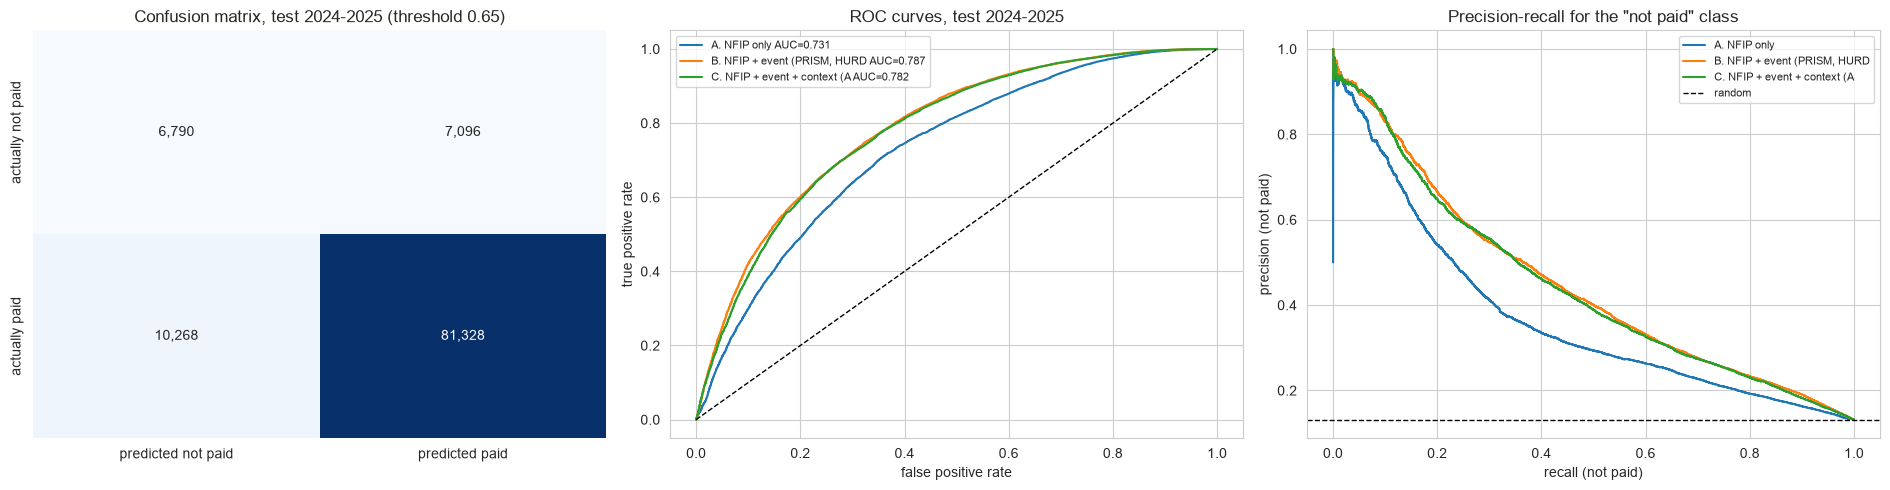

              precision    recall  f1-score   support

    not paid      0.398     0.489     0.439     13886
        paid      0.920     0.888     0.904     91596

    accuracy                          0.835    105482
   macro avg      0.659     0.688     0.671    105482
weighted avg      0.851     0.835     0.842    105482



In [18]:
final_scores = progression_scores['C. NFIP + event + context (ACS, NRI)']
final_predictions = (final_scores >= best_threshold).astype(int)
matrix = confusion_matrix(test_claims[TARGET], final_predictions)
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
sns.heatmap(matrix, annot=True, fmt=',', cmap='Blues', ax=axes[0], cbar=False,
            xticklabels=['predicted not paid', 'predicted paid'], yticklabels=['actually not paid', 'actually paid'])
axes[0].set_title(f'Confusion matrix, test 2024-2025 (threshold {best_threshold})')
for set_name, scores in progression_scores.items():
    false_positive_rate, true_positive_rate, _ = roc_curve(test_claims[TARGET], scores)
    axes[1].plot(false_positive_rate, true_positive_rate, label=f'{set_name[:28]} AUC={roc_auc_score(test_claims[TARGET], scores):.3f}')
    precision, recall, _ = precision_recall_curve(1 - test_claims[TARGET], -scores)
    axes[2].plot(recall, precision, label=f'{set_name[:28]}')
axes[1].plot([0, 1], [0, 1], 'k--', lw=1)
axes[1].set_xlabel('false positive rate')
axes[1].set_ylabel('true positive rate')
axes[1].set_title('ROC curves, test 2024-2025')
axes[1].legend(fontsize=8)
axes[2].axhline(1 - test_claims[TARGET].mean(), color='k', ls='--', lw=1, label='random')
axes[2].set_xlabel('recall (not paid)')
axes[2].set_ylabel('precision (not paid)')
axes[2].set_title('Precision-recall for the "not paid" class')
axes[2].legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIGURE_DIR / '03_rq1_confusion_roc_pr.png', dpi=120)
plt.show()
print(classification_report(test_claims[TARGET], final_predictions, target_names=['not paid', 'paid'], digits=3))

---
# Section 13: Which Features Drive the Prediction? (SHAP)

SHAP splits each prediction into additive contributions, one per feature, using ideas from game
theory (Shapley values). The summary plot shows, for each feature, how high and low values push the
prediction up or down.

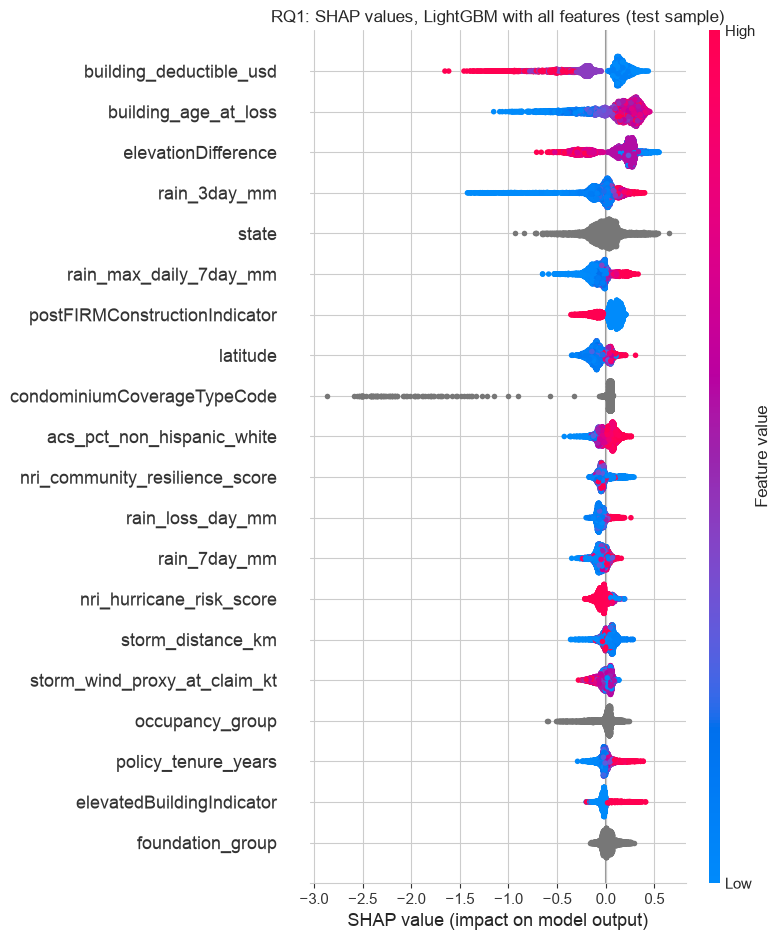

Mean |SHAP| share by data source (%):
NFIP       61.0
context    18.0
event      21.0

Top 12 features:
building_deductible_usd           0.2538
building_age_at_loss              0.2428
elevationDifference               0.2356
rain_3day_mm                      0.1354
state                             0.1093
rain_max_daily_7day_mm            0.1057
postFIRMConstructionIndicator     0.1036
latitude                          0.0931
condominiumCoverageTypeCode       0.0787
acs_pct_non_hispanic_white        0.0689
nri_community_resilience_score    0.0599
rain_loss_day_mm                  0.0573


In [19]:
shap_sample = to_category_frame(test_claims.sample(5000, random_state=SEED), numeric_C, categorical_C)
explainer = shap.TreeExplainer(lightgbm_C)
shap_values = explainer.shap_values(shap_sample)
if isinstance(shap_values, list):
    shap_values = shap_values[1]
shap.summary_plot(shap_values, shap_sample, max_display=20, show=False)
plt.title('RQ1: SHAP values, LightGBM with all features (test sample)')
plt.tight_layout()
plt.savefig(FIGURE_DIR / '03_rq1_shap_summary.png', dpi=110)
plt.show()

shap_importance = pd.Series(np.abs(shap_values).mean(axis=0), index=shap_sample.columns).sort_values(ascending=False)
shap_by_source = shap_importance.groupby(lambda c: 'NFIP' if c in NFIP_NUMERIC_FEATURES + NFIP_CATEGORICAL_FEATURES
                                         else 'event' if c in EVENT_FEATURES else 'context').sum()
print('Mean |SHAP| share by data source (%):')
print((shap_by_source / shap_by_source.sum() * 100).round(1).to_string())
shap_importance.round(4).to_csv(TABLE_DIR / '03_rq1_shap_importance.csv')
print('\nTop 12 features:')
print(shap_importance.head(12).round(4).to_string())

---
# Section 14: Where Does the Model Fail?

In [20]:
test_claims['rq1_score'] = final_scores
error_by_event = (test_claims.groupby('event_group')
                  .apply(lambda g: pd.Series({'claims': len(g), 'paid_rate': g[TARGET].mean(),
                                              'ROC_AUC': roc_auc_score(g[TARGET], g['rq1_score']) if g[TARGET].nunique() == 2 else np.nan}))
                  .sort_values('claims', ascending=False).head(10))
print(error_by_event.round(3).to_string())

                                claims  paid_rate  ROC_AUC
event_group                                               
Hurricane Helene               54363.0      0.916    0.818
Hurricane Milton               19233.0      0.819    0.703
no_named_event_2024             9481.0      0.764    0.744
no_named_event_2025             6014.0      0.806    0.779
Hurricane Beryl                 2318.0      0.657    0.696
Hurricane Debby                 2264.0      0.835    0.701
2025-04-Central U.S.-Flooding   2006.0      0.909    0.709
Hurricane Francine              1994.0      0.873    0.666
June South Florida Flooding     1356.0      0.849    0.701
Texas Spring Flooding           1012.0      0.888    0.695


In [21]:
results_rq1 = {'progression': progression_table.to_dict('records'), 'event_grouped_cv': cv_table.to_dict('records'),
               'threshold': best_threshold, 'model_comparison': comparison_table.to_dict('records')}
json.dump(results_rq1, open(TABLE_DIR / '03_rq1_results.json', 'w'), indent=2, default=float)

---
# Research Question -> Answer

> **RQ1. Can policy, building and external event information predict positive building payments?**

**Answer: partly. The model ranks claims usefully, and the external event data is what makes it work.**
(All numbers are on 2024-2025 claims, 105,137 claims, which the model never saw. 13.1% were not paid.)

| Evidence | NFIP only (A) | + event data (B) | + ACS/NRI context (C) |
|---|---|---|---|
| LightGBM ROC-AUC, time split | 0.715 | **0.786** | 0.772 |
| LightGBM PR-AUC "not paid" (random = 0.131) | 0.356 | **0.434** | 0.430 |
| Event-grouped 5-fold CV ROC-AUC | 0.675 +/- 0.047 | - | 0.728 +/- 0.016 |

- **NFIP facts alone are weak** (ROC 0.715, and only 0.675 when whole storms are held out).
- **PRISM rain, HURDAT2 storm and coast distance give the jump** (+0.07 ROC, PR-AUC from 0.36 to 0.43).
  The first split of every tree is 3-day rain: claims with less than about 40-50 mm of rain are
  paid only 52-60% of the time, against 81-83% above it.
- **ACS/NRI context does not help on the time split** (0.772 vs 0.786). It helps the event-grouped CV
  and makes it more stable, but neighbourhood values partly act as location IDs (notebook 02).
- **Course models:** tree 0.665, naive Bayes 0.640, k-NN 0.705, logistic 0.696, SVM 0.715, MLP 0.761,
  LightGBM 0.773 (all on set C). The MLP comes close to LightGBM but does not beat it (Lecture 14).
- **Operating point:** a threshold of 0.65 chosen on 2023 gives, on 2024-2025, recall 0.47 and precision
  0.40 for "not paid" (3x the base rate), and balanced accuracy 0.68.
- **SHAP:** 61.5% NFIP, 20.3% event, 18.2% context. Top drivers: deductible, building age, elevation
  difference, 3-day rain, state.
- **Per event:** ROC 0.81 on Helene, but 0.67-0.74 on most other events. Each storm behaves differently.
- **Why not higher:** 44% of the SVM training claims are support vectors, so the classes overlap a lot.
  Many unpaid claims are "below deductible" or "not actual flood". That depends on what happened inside
  the house, which we cannot know at filing time without leakage.
- **Practical reading:** the model is good for triage (which claims to inspect first). It cannot replace
  the adjuster.